✅ Image loaded: (10, 149)
✅ Output saved at: ultra_clear.png


(np.float64(-0.5), np.float64(595.5), np.float64(39.5), np.float64(-0.5))

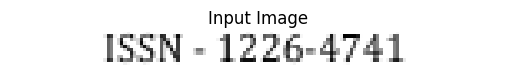

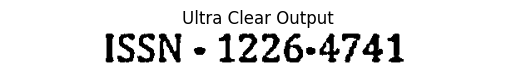

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# CONFIG
# =========================
path = r"debug_lines/line_1.png"  # <-- CHANGE THIS

# =========================
# SAFE IMAGE LOAD
# =========================
if not os.path.exists(path):
    raise FileNotFoundError(f"❌ File not found: {path}")

img = cv2.imread(path, 0)

if img is None:
    raise ValueError("❌ Failed to load image. Check file format/path.")

print("✅ Image loaded:", img.shape)

# =========================
# STEP 1: UPSCALE
# =========================
img_up = cv2.resize(img, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)

# =========================
# STEP 2: DENOISE
# =========================
img_denoise = cv2.fastNlMeansDenoising(img_up, None, 10, 7, 21)

# =========================
# STEP 3: SHARPEN
# =========================
kernel = np.array([[0,-1,0],
                   [-1,5,-1],
                   [0,-1,0]])
img_sharp = cv2.filter2D(img_denoise, -1, kernel)

# =========================
# STEP 4: THRESHOLD (CLEAR TEXT)
# =========================
img_thresh = cv2.adaptiveThreshold(
    img_sharp, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31, 5
)

# =========================
# SAVE OUTPUT
# =========================
output_path = "ultra_clear.png"
cv2.imwrite(output_path, img_thresh)

print("✅ Output saved at:", output_path)

# =========================
# DISPLAY RESULTS
# =========================
plt.figure()
plt.imshow(img, cmap='gray')
plt.title("Input Image")
plt.axis('off')

plt.figure()
plt.imshow(img_thresh, cmap='gray')
plt.title("Ultra Clear Output")
plt.axis('off')

In [6]:
# Best Image processing model